In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

print("="*70)
print("ROSSMANN STORE SALES - DATA EXPLORATION")
print("="*70)

ROSSMANN STORE SALES - DATA EXPLORATION


In [2]:
# Load all three datasets
train = pd.read_csv('../data/raw/train.csv', parse_dates=['Date'])
test = pd.read_csv('../data/raw/test.csv', parse_dates=['Date'])
store = pd.read_csv('../data/raw/store.csv')

print("\n📊 DATASET SHAPES")
print("="*70)
print(f"Train: {train.shape[0]:,} rows × {train.shape[1]} columns")
print(f"Test:  {test.shape[0]:,} rows × {test.shape[1]} columns")
print(f"Store: {store.shape[0]:,} rows × {store.shape[1]} columns")

print(f"\nDate Range (Train): {train['Date'].min()} to {train['Date'].max()}")
print(f"Date Range (Test):  {test['Date'].min()} to {test['Date'].max()}")
print(f"Total Stores: {train['Store'].nunique()}")


📊 DATASET SHAPES
Train: 1,017,209 rows × 9 columns
Test:  41,088 rows × 8 columns
Store: 1,115 rows × 10 columns

Date Range (Train): 2013-01-01 00:00:00 to 2015-07-31 00:00:00
Date Range (Test):  2015-08-01 00:00:00 to 2015-09-17 00:00:00
Total Stores: 1115


In [3]:
print("\n📋 TRAIN DATASET COLUMNS")
print("="*70)
print(train.info())

print("\n📋 STORE DATASET COLUMNS")
print("="*70)
print(store.info())


📋 TRAIN DATASET COLUMNS


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[ns]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[ns](1), int64(7), object(1)
memory usage: 69.8+ MB
None

📋 STORE DATASET COLUMNS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     ----------

In [4]:
print("\n👀 TRAIN DATA SAMPLE")
print("="*70)
display(train.head(10))

print("\n👀 STORE DATA SAMPLE")
print("="*70)
display(store.head(10))


👀 TRAIN DATA SAMPLE


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
5,6,5,2015-07-31,5651,589,1,1,0,1
6,7,5,2015-07-31,15344,1414,1,1,0,1
7,8,5,2015-07-31,8492,833,1,1,0,1
8,9,5,2015-07-31,8565,687,1,1,0,1
9,10,5,2015-07-31,7185,681,1,1,0,1



👀 STORE DATA SAMPLE


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
5,6,a,a,310.0,12.0,2013.0,0,NaN,NaN,NaN
6,7,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
7,8,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
8,9,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
9,10,a,a,3160.0,9.0,2009.0,0,NaN,NaN,NaN


In [5]:
print("\n🔍 MISSING VALUES ANALYSIS")
print("="*70)

print("\nTrain Dataset:")
missing_train = train.isnull().sum()
print(missing_train[missing_train > 0])
if missing_train.sum() == 0:
    print("✅ No missing values in train!")

print("\nTest Dataset:")
missing_test = test.isnull().sum()
print(missing_test[missing_test > 0])

print("\nStore Dataset:")
missing_store = store.isnull().sum()
print(missing_store[missing_store > 0])
if missing_store.sum() > 0:
    print(f"\n⚠️ Store data has {missing_store.sum()} missing values")


🔍 MISSING VALUES ANALYSIS

Train Dataset:
Series([], dtype: int64)
✅ No missing values in train!

Test Dataset:
Open    11
dtype: int64

Store Dataset:


CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64



⚠️ Store data has 2343 missing values


In [6]:
print("\n💰 SALES (TARGET VARIABLE) ANALYSIS")
print("="*70)
print(train['Sales'].describe())

print(f"\nTotal Sales: {train['Sales'].sum():,.2f}")
print(f"Average Daily Sales: {train['Sales'].mean():,.2f}")
print(f"Median Daily Sales: {train['Sales'].median():,.2f}")
print(f"Max Daily Sales: {train['Sales'].max():,.2f}")
print(f"Stores with Sales = 0: {(train['Sales'] == 0).sum():,}")


💰 SALES (TARGET VARIABLE) ANALYSIS


count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

Total Sales: 5,873,180,623.00
Average Daily Sales: 5,773.82
Median Daily Sales: 5,744.00
Max Daily Sales: 41,551.00
Stores with Sales = 0: 172,871


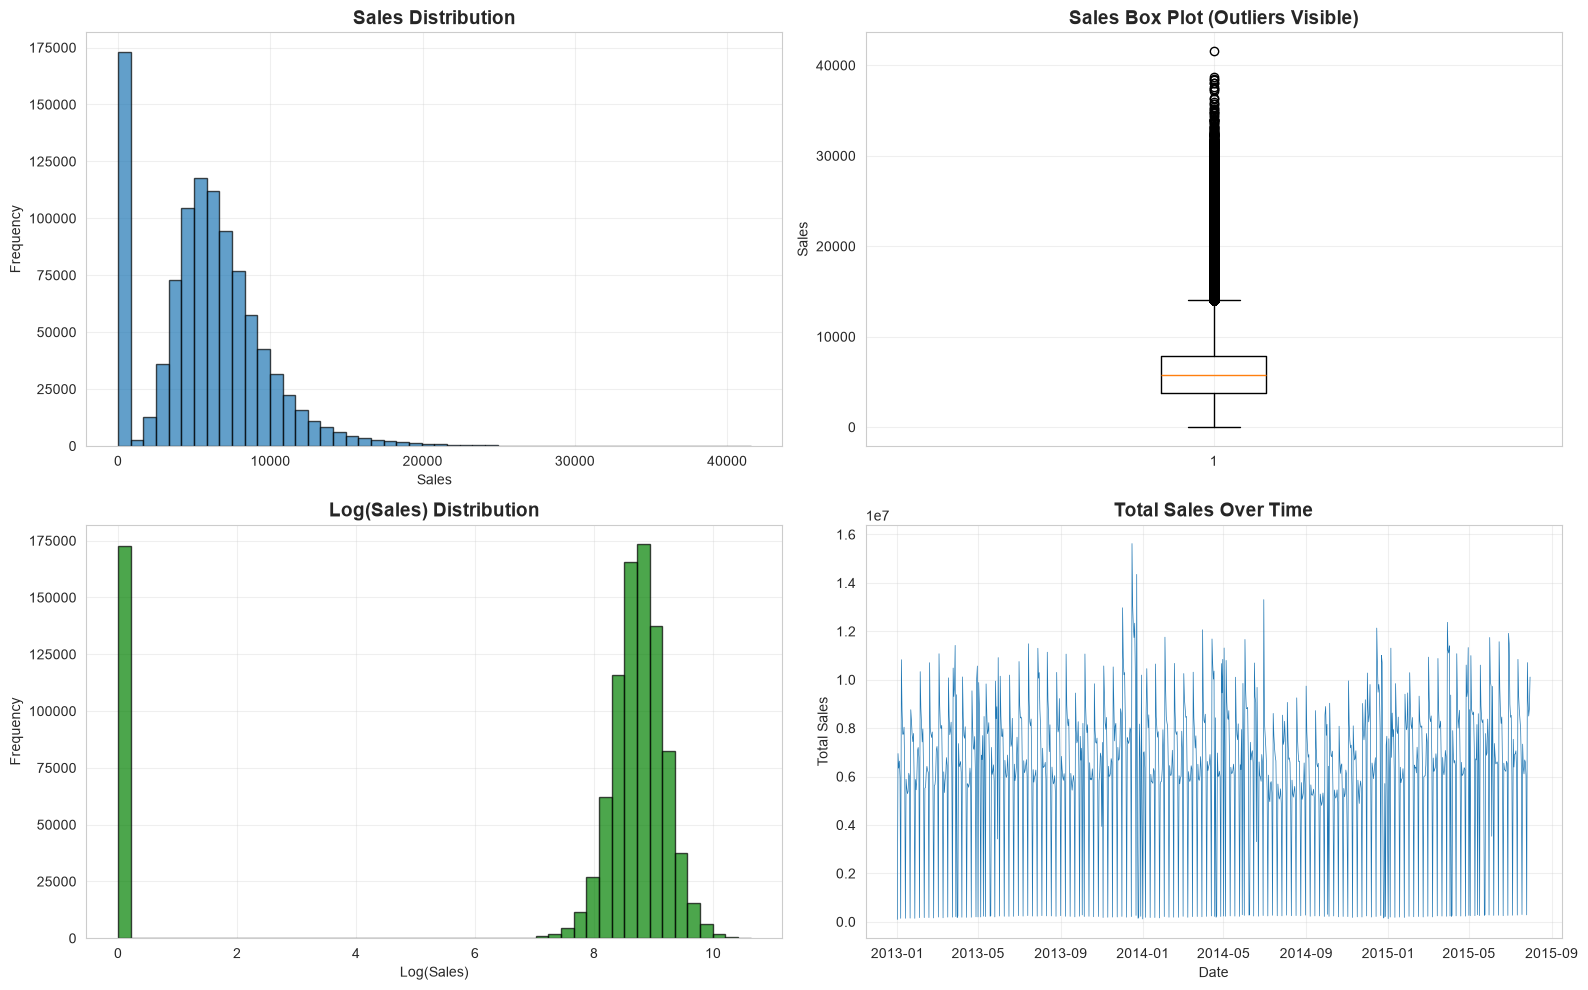

In [7]:
# Sales Distribution
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Histogram
axes[0, 0].hist(train['Sales'], bins=50, edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Sales Distribution', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Sales')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].grid(alpha=0.3)

# Box plot
axes[0, 1].boxplot(train['Sales'])
axes[0, 1].set_title('Sales Box Plot (Outliers Visible)', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Sales')
axes[0, 1].grid(alpha=0.3)

# Log distribution
axes[1, 0].hist(np.log1p(train['Sales']), bins=50, edgecolor='black', alpha=0.7, color='green')
axes[1, 0].set_title('Log(Sales) Distribution', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Log(Sales)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(alpha=0.3)

# Sales over time
daily_sales = train.groupby('Date')['Sales'].sum()
axes[1, 1].plot(daily_sales.index, daily_sales.values, linewidth=0.5)
axes[1, 1].set_title('Total Sales Over Time', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Date')
axes[1, 1].set_ylabel('Total Sales')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Merge train with store information
df = train.merge(store, on='Store', how='left')
print(f"✅ Merged dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

✅ Merged dataset shape: (1017209, 18)
Columns: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


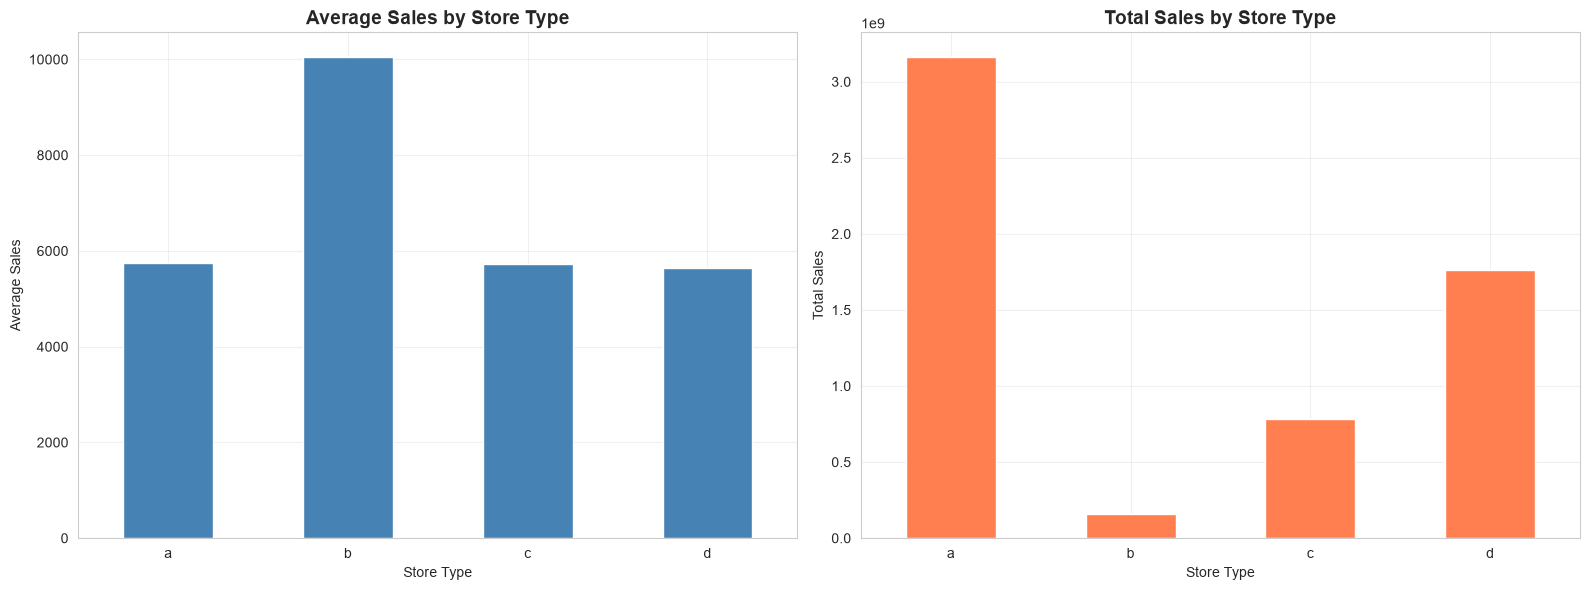


Store Type Sales Summary:
                   mean         sum
StoreType                          
a           5738.179710  3165334859
b          10058.837334   159231395
c           5723.629246   783221426
d           5641.819243  1765392943


In [9]:
# Sales by Store Type
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

store_type_sales = df.groupby('StoreType')['Sales'].agg(['mean', 'sum'])
store_type_sales['mean'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Average Sales by Store Type', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Store Type')
axes[0].set_ylabel('Average Sales')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].grid(alpha=0.3)

store_type_sales['sum'].plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Total Sales by Store Type', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Store Type')
axes[1].set_ylabel('Total Sales')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nStore Type Sales Summary:")
print(store_type_sales)

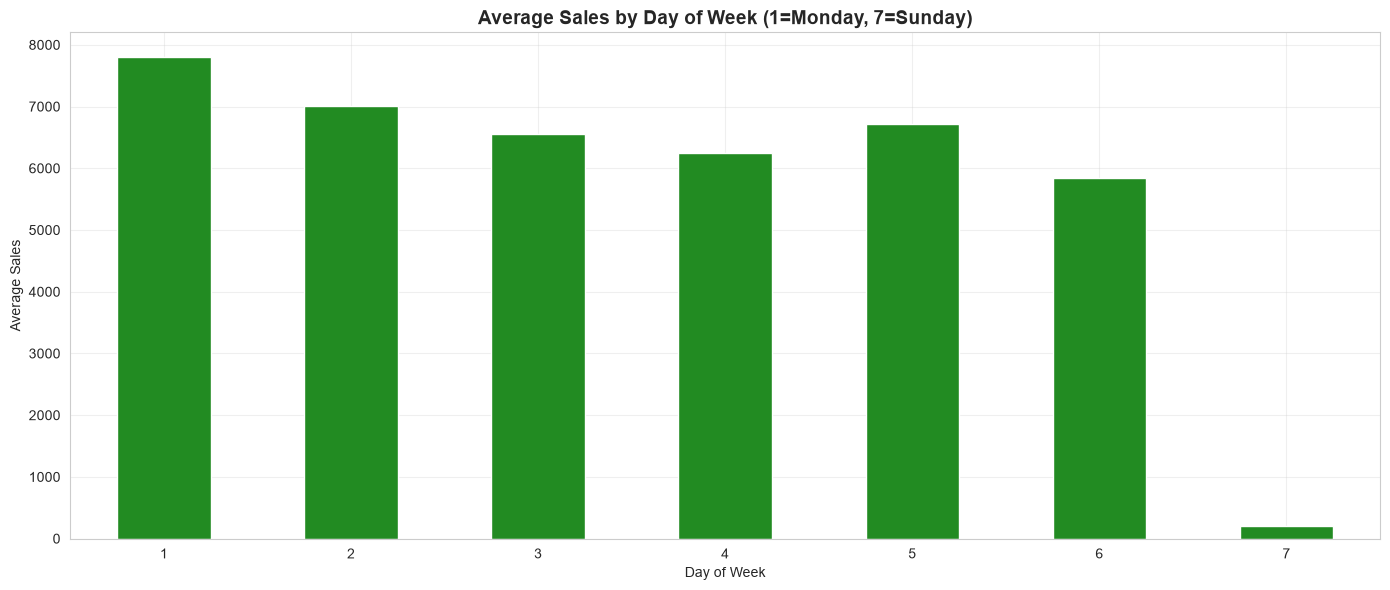


Day of Week Sales:
  Mon: 7,809.04
  Tue: 7,005.24
  Wed: 6,555.88
  Thu: 6,247.58
  Fri: 6,723.27
  Sat: 5,847.56
  Sun: 204.18


In [10]:
# Sales by Day of Week
plt.figure(figsize=(14, 6))
dow_sales = df.groupby('DayOfWeek')['Sales'].mean()
dow_sales.plot(kind='bar', color='forestgreen')
plt.title('Average Sales by Day of Week (1=Monday, 7=Sunday)', fontsize=14, fontweight='bold')
plt.xlabel('Day of Week')
plt.ylabel('Average Sales')
plt.xticks(rotation=0)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nDay of Week Sales:")
for day, sales in dow_sales.items():
    day_name = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'][day-1]
    print(f"  {day_name}: {sales:,.2f}")

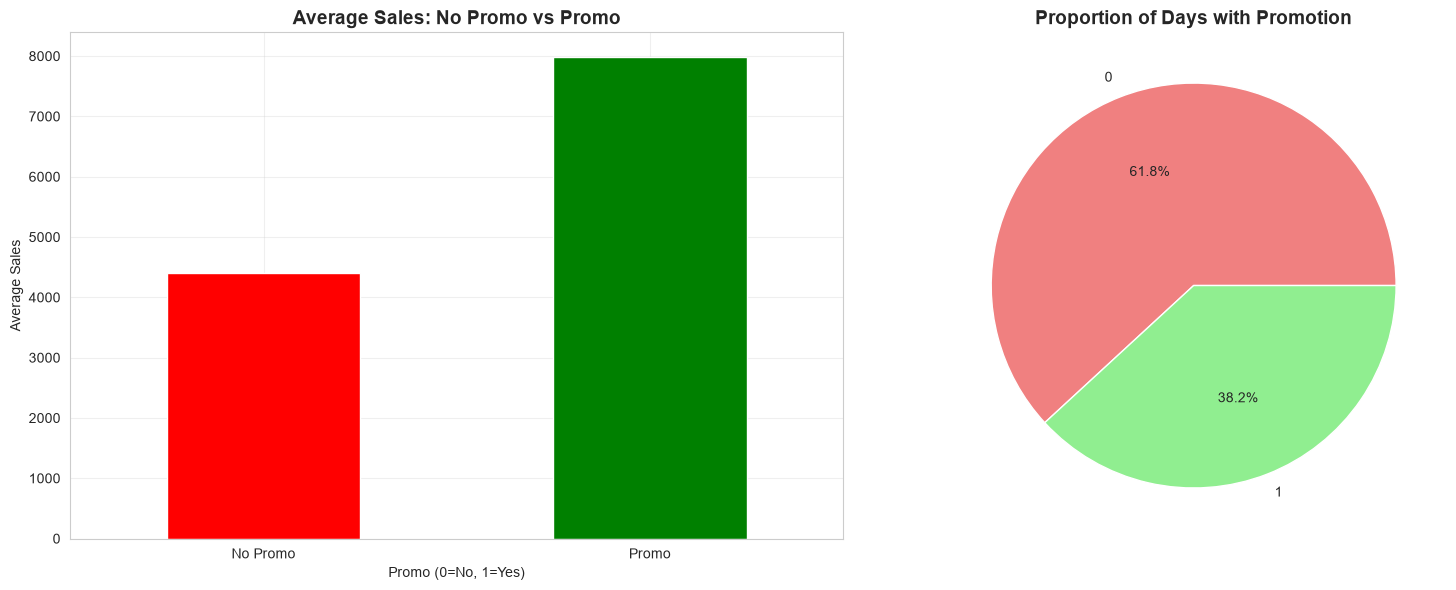


Average Sales WITHOUT Promo: 4,406.05
Average Sales WITH Promo: 7,991.15
Promo Impact: +81.4%


In [11]:
# Promotion Impact
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

promo_sales = df.groupby('Promo')['Sales'].mean()
promo_sales.plot(kind='bar', ax=axes[0], color=['red', 'green'])
axes[0].set_title('Average Sales: No Promo vs Promo', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Promo (0=No, 1=Yes)')
axes[0].set_ylabel('Average Sales')
axes[0].set_xticklabels(['No Promo', 'Promo'], rotation=0)
axes[0].grid(alpha=0.3)

# Promo distribution
df['Promo'].value_counts().plot(kind='pie', ax=axes[1], autopct='%1.1f%%', colors=['lightcoral', 'lightgreen'])
axes[1].set_title('Proportion of Days with Promotion', fontsize=14, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print(f"\nAverage Sales WITHOUT Promo: {promo_sales[0]:,.2f}")
print(f"Average Sales WITH Promo: {promo_sales[1]:,.2f}")
print(f"Promo Impact: +{((promo_sales[1]/promo_sales[0] - 1) * 100):.1f}%")

In [12]:
# Open vs Closed Analysis
print("\n🏪 STORE OPEN/CLOSED ANALYSIS")
print("="*70)

open_counts = train['Open'].value_counts()
print(f"\nOpen Days: {open_counts[1]:,}")
print(f"Closed Days: {open_counts[0]:,}")
print(f"Percentage Open: {(open_counts[1]/(open_counts[0]+open_counts[1])*100):.2f}%")

# Check if closed stores have sales
closed_with_sales = train[(train['Open'] == 0) & (train['Sales'] > 0)]
print(f"\n⚠️ Closed days with Sales > 0: {len(closed_with_sales)}")


🏪 STORE OPEN/CLOSED ANALYSIS

Open Days: 844,392
Closed Days: 172,817
Percentage Open: 83.01%

⚠️ Closed days with Sales > 0: 0


In [13]:
print("\n📝 KEY INSIGHTS FROM EXPLORATION")
print("="*70)

insights = """
1. DATA VOLUME
   - Training data: 1,017,209 store-day records across 1,115 stores
   - Time period: 2013-01-01 to 2015-07-31, daily granularity

2. SALES PATTERNS
   - Average daily sales: ~5,774 over all rows, ~6,956 on open days
   - Weekly seasonality: Monday is the strongest weekday; the Sunday average
     is near zero because only 33 stores ever open on Sundays
   - Promotion days average +81% over non-promo days across all rows
     (+39% on open days only)

3. MISSING DATA
   - store.csv: 2,343 missing values (competition and Promo2 fields)
   - test.csv: 11 missing values in Open

4. STORE CHARACTERISTICS
   - 4 store types (a, b, c, d); type 'b' has the highest average sales
   - 3 assortment levels

5. CLOSED STORES
   - 172,817 records (17.0%) are closed days (Open=0), all with zero sales
   - These are filtered out for training, along with 54 open days with zero sales

6. NEXT STEPS
   - Clean and preprocess data
   - Handle missing values
   - Create time-based features
   - Engineer lag and rolling features
"""

print(insights)


📝 KEY INSIGHTS FROM EXPLORATION

1. DATA VOLUME
   - Training data: 1,017,209 store-day records across 1,115 stores
   - Time period: 2013-01-01 to 2015-07-31, daily granularity

2. SALES PATTERNS
   - Average daily sales: ~5,774 over all rows, ~6,956 on open days
   - Weekly seasonality: Monday is the strongest weekday; the Sunday average
     is near zero because only 33 stores ever open on Sundays
   - Promotion days average +81% over non-promo days across all rows
     (+39% on open days only)

3. MISSING DATA
   - store.csv: 2,343 missing values (competition and Promo2 fields)
   - test.csv: 11 missing values in Open

4. STORE CHARACTERISTICS
   - 4 store types (a, b, c, d); type 'b' has the highest average sales
   - 3 assortment levels

5. CLOSED STORES
   - 172,817 records (17.0%) are closed days (Open=0), all with zero sales
   - These are filtered out for training, along with 54 open days with zero sales

6. NEXT STEPS
   - Clean and preprocess data
   - Handle missing value